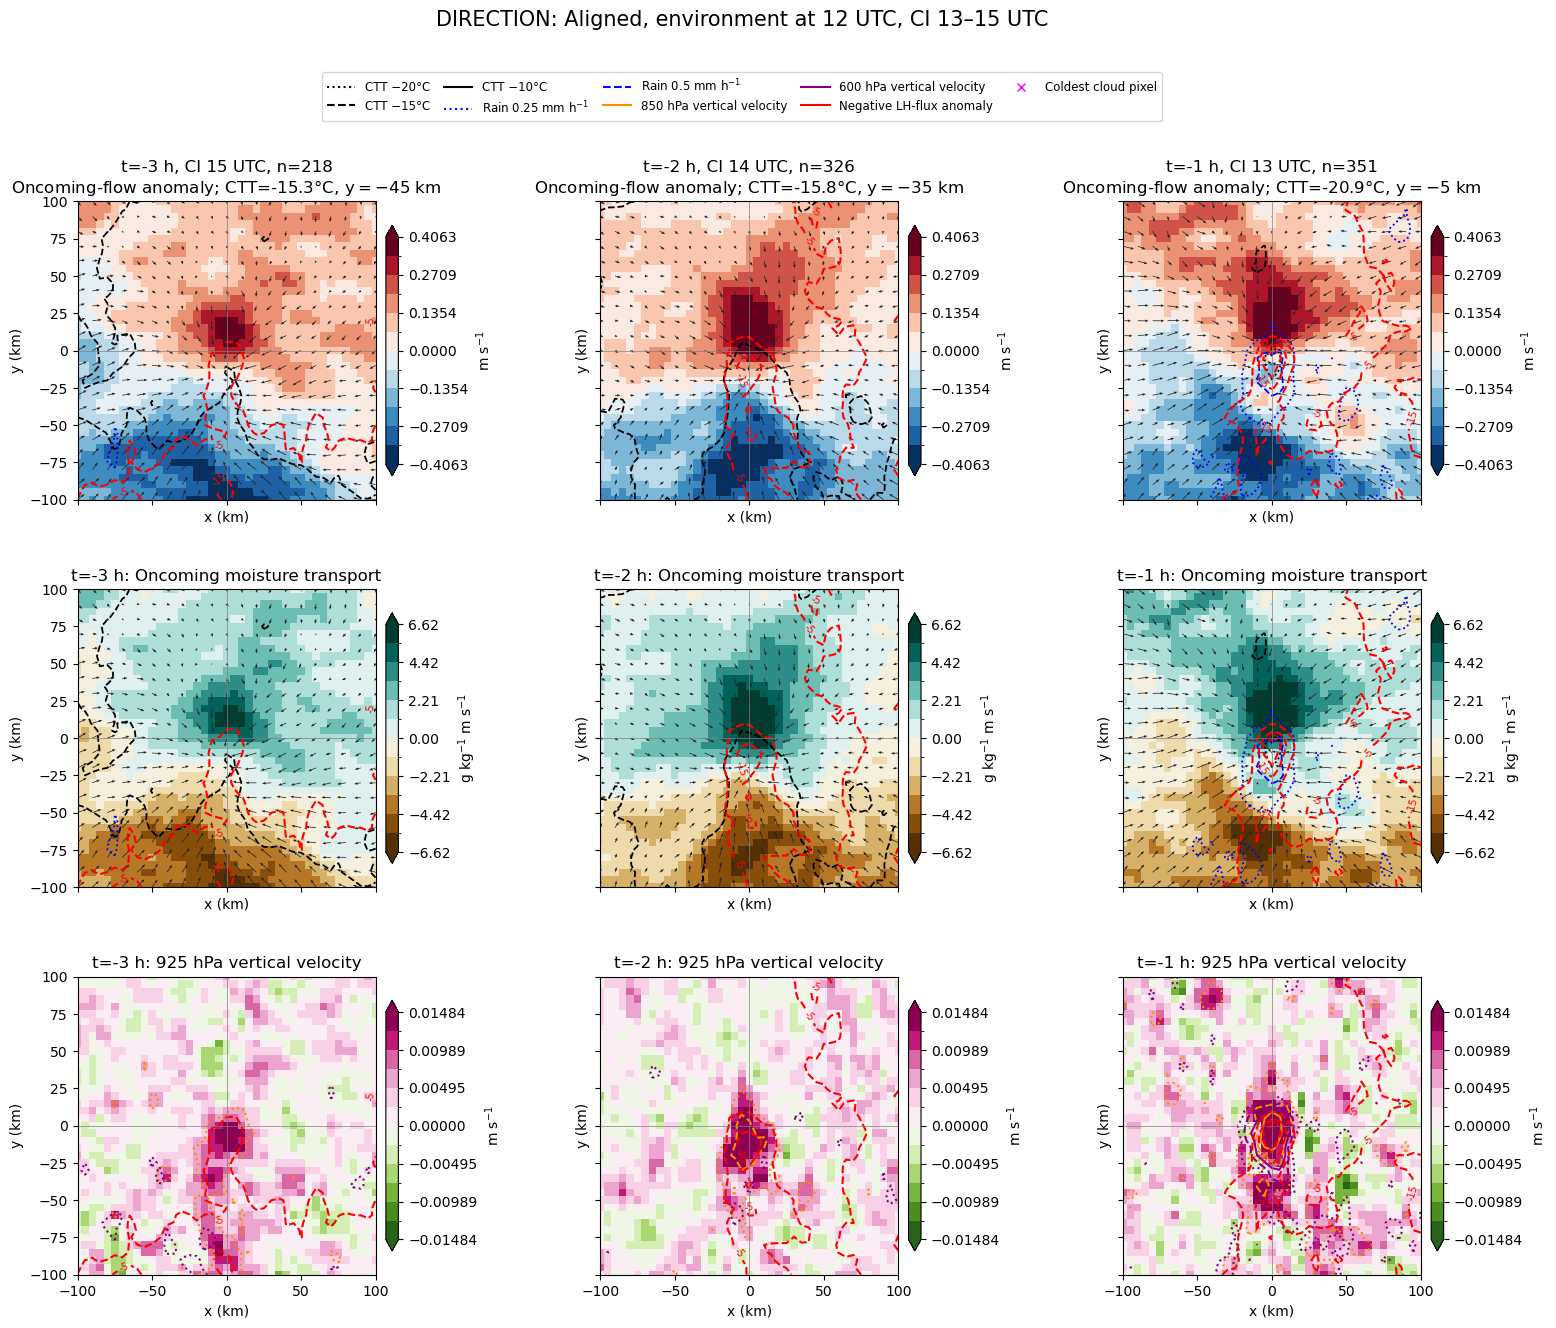

Saved: /gws/ssde/j25b/kscale/USERS/cklein/umbrella/full_composites_200km_fluxes_fixed12/composite_aligned_3x3_simplified_oncoming_flow_fixed12.jpg


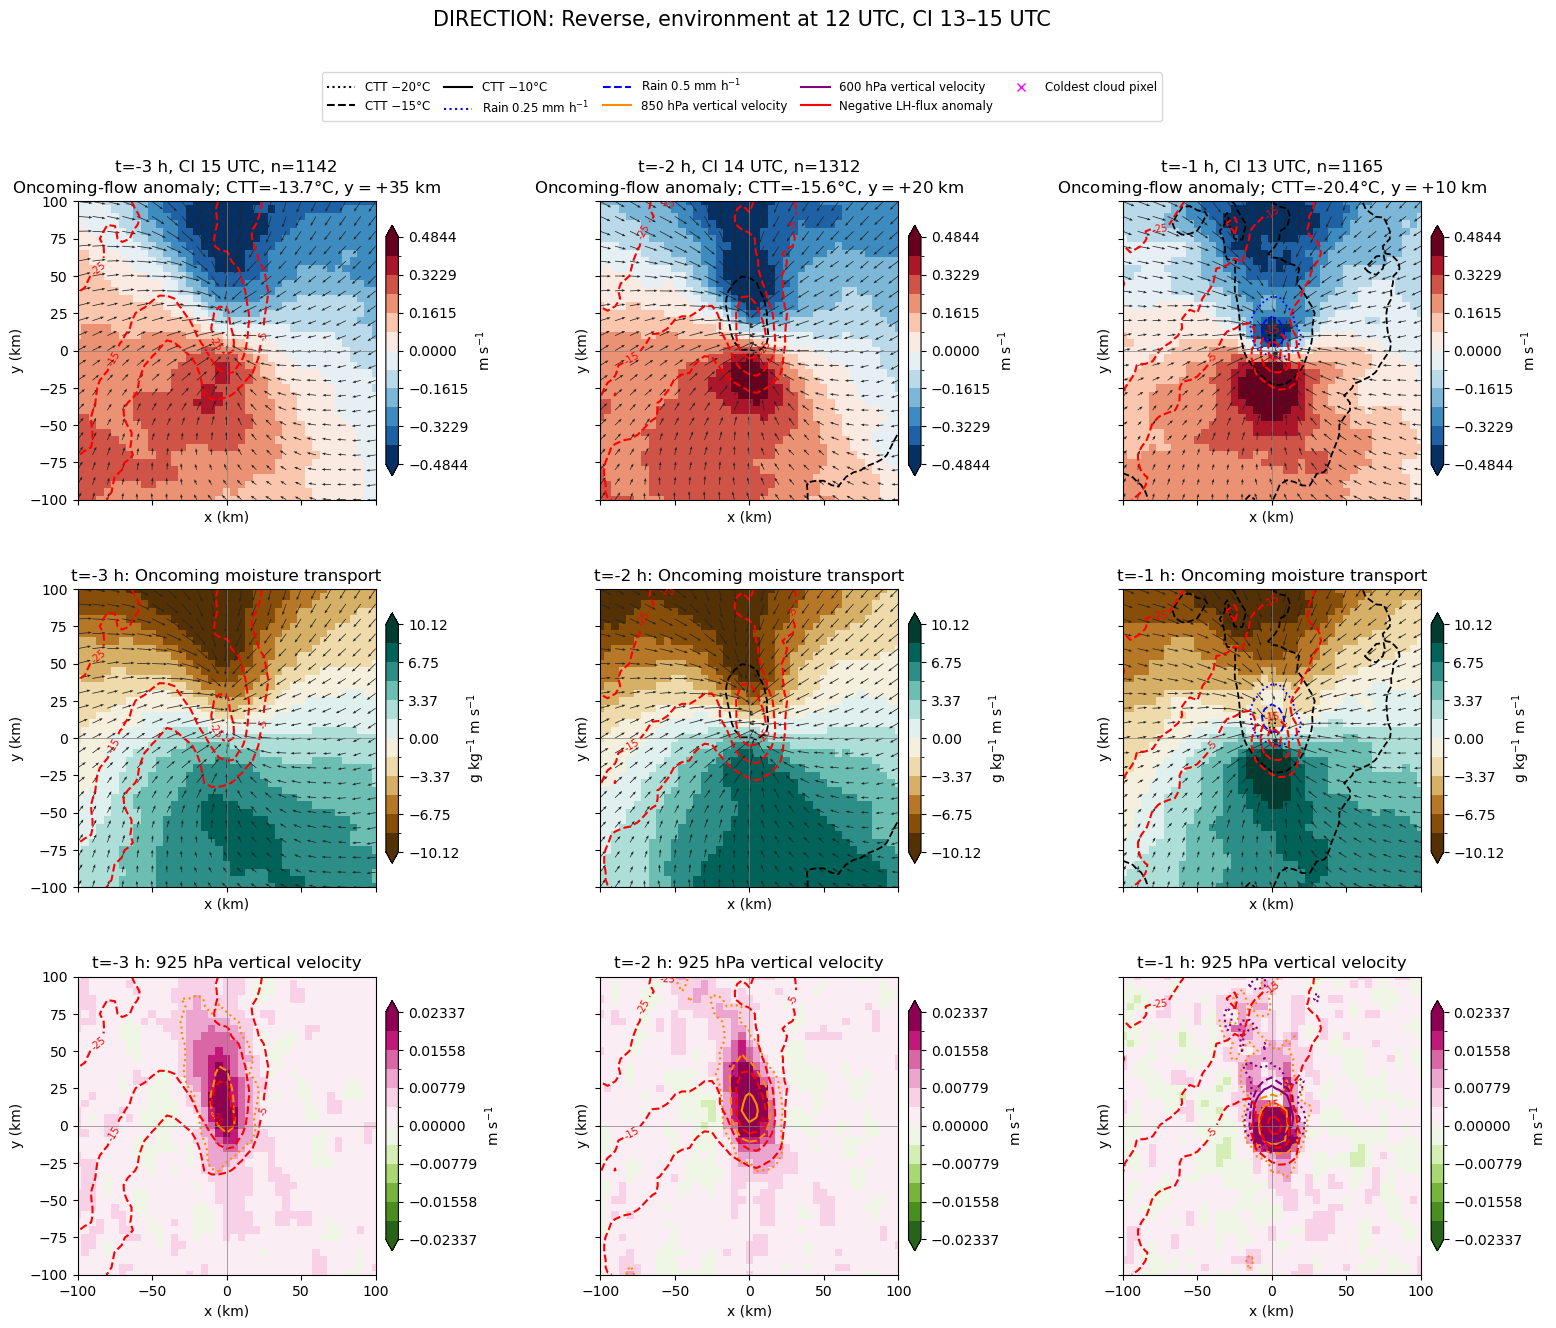

Saved: /gws/ssde/j25b/kscale/USERS/cklein/umbrella/full_composites_200km_fluxes_fixed12/composite_reverse_3x3_simplified_oncoming_flow_fixed12.jpg


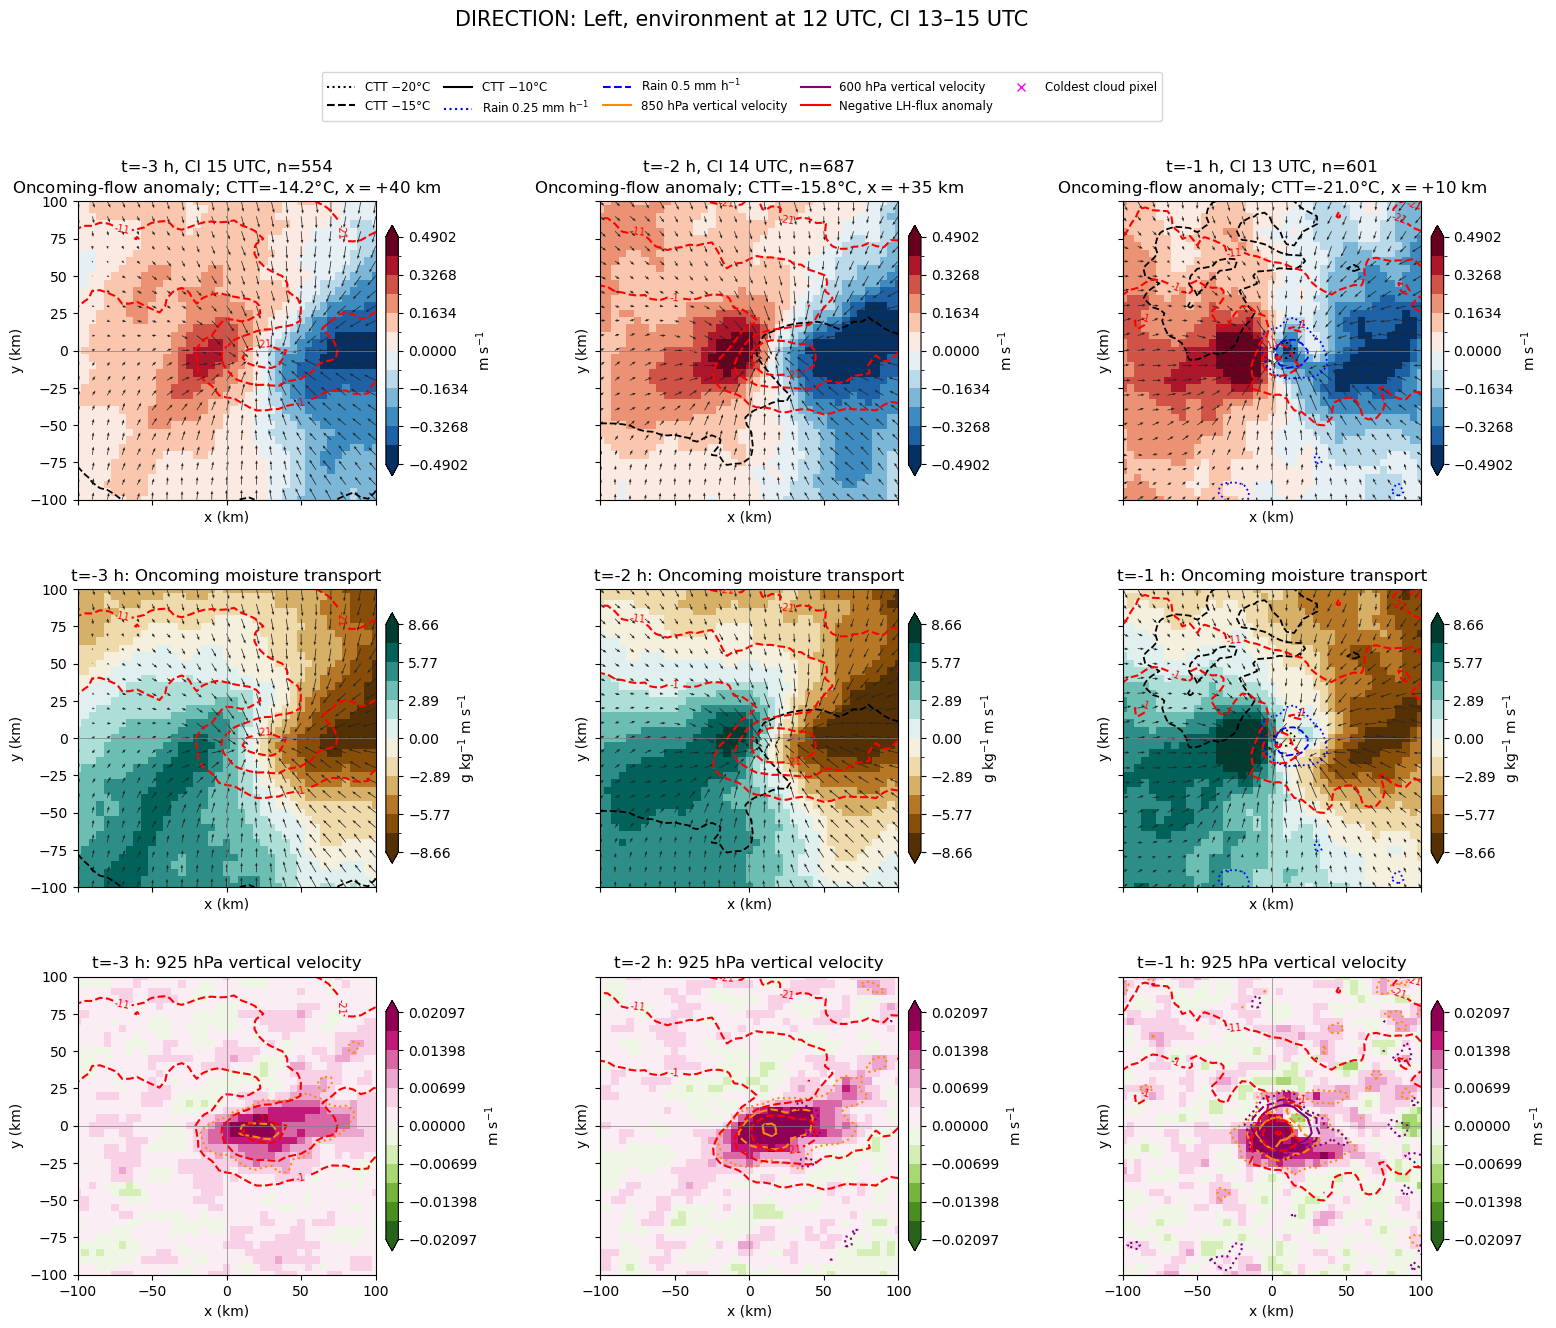

Saved: /gws/ssde/j25b/kscale/USERS/cklein/umbrella/full_composites_200km_fluxes_fixed12/composite_left_3x3_simplified_oncoming_flow_fixed12.jpg


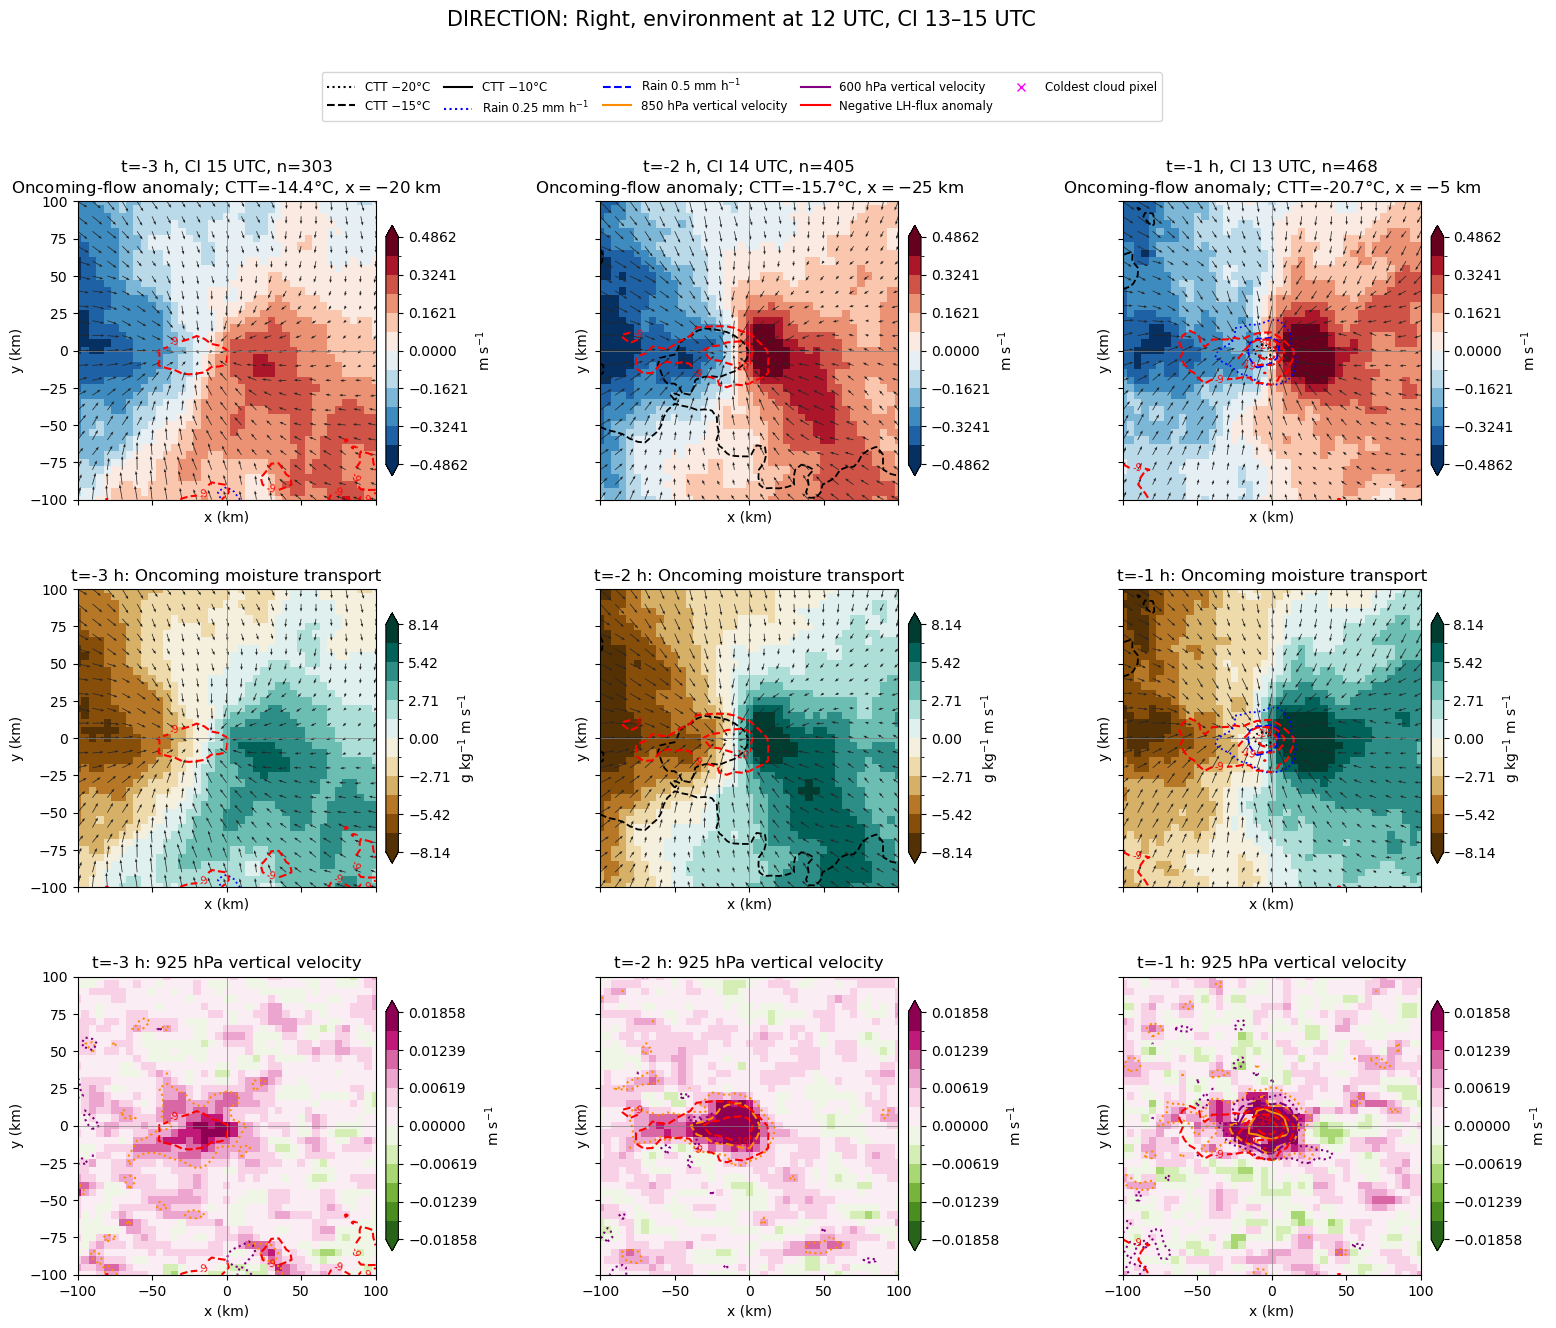

Saved: /gws/ssde/j25b/kscale/USERS/cklein/umbrella/full_composites_200km_fluxes_fixed12/composite_right_3x3_simplified_oncoming_flow_fixed12.jpg


In [6]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.colors import BoundaryNorm


OUTPUT_ROOT = Path("/gws/ssde/j25b/kscale/USERS/cklein/umbrella/full_composites_200km_fluxes_fixed12")

FIXED12_CI_HOURS = {-3: 15, -2: 14, -1: 13}
PLOT_LAGS = [-3, -2, -1]
DIRECTIONS = ["aligned", "reverse", "left", "right"]

PLOT_HALF_WIDTH_KM = 100
CTT_SEARCH_BOX_POINTS = 20
N_COLOUR_BINS = 12

CTT_LEVELS = [-20, -15, -10]                   
RAIN_LEVELS = [0.25, 0.5]                     
W850_LEVELS = [0.02, 0.05, 0.10]              
W600_LEVELS = [0.02, 0.05, 0.10]              

LH_FLUX_COLOUR = "red"
LH_FLUX_OFFSETS = [30.0, 20.0, 10.0]           
W850_COLOUR = "darkorange"
W600_COLOUR = "purple"

CLOUD_COLOUR = "magenta"
WIND_VECTOR_STEP = 2
WIND_VECTOR_SCALE = 10


def lag_tag(lag):
    return f"lag_{lag:+d}h".replace("+", "p").replace("-", "m")


def load_composite(direction, lag):
    ci_hour = FIXED12_CI_HOURS[lag]
    tag = lag_tag(lag)
    nc_file = OUTPUT_ROOT / tag / f"CI{ci_hour:02d}_200km_fluxes_{tag}.nc"

    if not nc_file.exists():
        raise FileNotFoundError(nc_file)

    with xr.open_dataset(nc_file) as ds:
        return ds.sel(category=direction).load()


def spatial_anomaly(data):
    data = np.asarray(data, dtype=float)
    return data - np.nanmean(data)


def central_indices(coordinate, size):
    centre = int(np.nanargmin(np.abs(coordinate)))
    start = max(0, centre - size // 2)
    stop = min(coordinate.size, start + size)
    start = max(0, stop - size)
    return np.arange(start, stop)


def prepare_composite(composite, direction):
    #### wind calculations

    x = np.asarray(composite["x_km"].values, dtype=float)
    y = np.asarray(composite["y_km"].values, dtype=float)
    X, Y = np.meshgrid(x, y)

    ctt = np.asarray(composite["ctt"].values, dtype=float)
    rain = np.asarray(composite["rain"].values, dtype=float)
    q_low = np.asarray(composite["q_low"].values, dtype=float)

    u10 = np.asarray(composite["u10"].values, dtype=float)
    v10 = np.asarray(composite["v10"].values, dtype=float)
    u600 = np.asarray(composite["u600"].values, dtype=float)
    v600 = np.asarray(composite["v600"].values, dtype=float)

    plot_box = (np.abs(X) <= PLOT_HALF_WIDTH_KM) & (np.abs(Y) <= PLOT_HALF_WIDTH_KM)
    valid_wind = plot_box & np.isfinite(u10) & np.isfinite(v10)
    valid_q = plot_box & np.isfinite(q_low)

    mean_u10 = float(np.nanmean(u10[valid_wind]))
    mean_v10 = float(np.nanmean(v10[valid_wind]))
    mean_q = float(np.nanmean(q_low[valid_q]))

    # Local 600 hPa wind direction
    direction600 = np.arctan2(v600, u600)

    # Actual 600hpa minus 10m wind shear and 'mean' shear where 10m wind is domain mean
    shear_u, shear_v = u600 - u10, v600 - v10
    mean_shear_u, mean_shear_v = u600 - mean_u10, v600 - mean_v10

    # Along-flow shear, interpreted as cloud-relative oncoming flow
    raw_headwind = shear_u * np.cos(direction600) + shear_v * np.sin(direction600)
    mean_headwind = mean_shear_u * np.cos(direction600) + mean_shear_v * np.sin(direction600)
    headwind_anomaly = raw_headwind - mean_headwind ## note: this is almost simply the 10m wind anomaly, but taking into account the direction/sign of the 600hPa wind at every pixel.

    # Low-level wind anomaly vectors shown by black arrows
    wind_anomaly_u, wind_anomaly_v = u10 - mean_u10, v10 - mean_v10

    # Moisture-weighted oncoming-flow anomaly.
    moisture_anomaly = q_low * raw_headwind - mean_q * mean_headwind  # moisture flow is just multiplied by q / box mean q

    return {
        "x": x, "y": y, "X": X, "Y": Y, "ctt": ctt, "rain": rain,
        "wind_anomaly_u": wind_anomaly_u, "wind_anomaly_v": wind_anomaly_v,
        "raw_headwind": raw_headwind, "headwind_anomaly": headwind_anomaly,
        "moisture_anomaly": moisture_anomaly,
        "w925": np.asarray(composite["w925"].values, dtype=float),
        "w850": np.asarray(composite["w850"].values, dtype=float),
        "w600": np.asarray(composite["w600"].values, dtype=float),
        "lh_anomaly": spatial_anomaly(composite["lh_flux"].values),
        "cloud": find_cloud(x, y, ctt, direction),
        "n_cases": int(composite["n_cases"].item()),
    }


def shared_levels(prepared, field, percentile=99):
    values = []

    for item in prepared.values():
        box = (np.abs(item["X"]) <= PLOT_HALF_WIDTH_KM) & (np.abs(item["Y"]) <= PLOT_HALF_WIDTH_KM)
        selected = item[field][box & np.isfinite(item[field])]
        if selected.size:
            values.append(selected)

    limit = np.nanpercentile(np.abs(np.concatenate(values)), percentile)
    return np.linspace(-max(float(limit), 1e-12), max(float(limit), 1e-12), N_COLOUR_BINS + 1)


def lh_levels(prepared):
    values = []

    for item in prepared.values():
        box = (np.abs(item["X"]) <= PLOT_HALF_WIDTH_KM) & (np.abs(item["Y"]) <= PLOT_HALF_WIDTH_KM)
        selected = item["lh_anomaly"][box & np.isfinite(item["lh_anomaly"])]
        if selected.size:
            values.append(selected)

    most_negative = float(np.nanmin(np.concatenate(values)))
    return np.unique(np.sort([level for level in (most_negative + np.array(LH_FLUX_OFFSETS)) if level < 0]))


def add_cloud_overlays(ax, item):
    ax.contour(item["X"], item["Y"], item["ctt"], levels=CTT_LEVELS, colors="black",
               linestyles=[":", "--", "-"], linewidths=1.3)
    ax.contour(item["X"], item["Y"], item["rain"], levels=RAIN_LEVELS, colors="blue",
               linestyles=[":", "--"], linewidths=1.3)


def add_lh_contours(ax, item, levels):
    data = item["lh_anomaly"]
    levels_here = levels[(levels >= np.nanmin(data)) & (levels <= np.nanmax(data))]

    if levels_here.size:
        contours = ax.contour(item["X"], item["Y"], data, levels=levels_here,
                              colors=LH_FLUX_COLOUR, linewidths=1.5)
        ax.clabel(contours, fmt="%.0f", fontsize=7, colors=LH_FLUX_COLOUR)


def add_wind_vectors(ax, item):
    step = WIND_VECTOR_STEP
    ax.quiver(item["X"][::step, ::step], item["Y"][::step, ::step],
              item["wind_anomaly_u"][::step, ::step], item["wind_anomaly_v"][::step, ::step],
              color="0.15", scale=WIND_VECTOR_SCALE, width=0.0025, headwidth=3.5, headlength=4.5)


# def add_cloud_marker(ax, item):
#     ax.plot(item["cloud"]["x"], item["cloud"]["y"], marker="x", color=CLOUD_COLOUR,
#             markersize=5, markeredgewidth=1, linestyle="none", zorder=10)


def format_panel(ax, title):
    ax.axhline(0, color="0.5", lw=0.5)
    ax.axvline(0, color="0.5", lw=0.5)
    ax.set(title=title, xlabel="x (km)", ylabel="y (km)",
           xlim=(-100, 100), ylim=(-100, 100), aspect="equal")


def add_colourbar(fig, ax, shading, levels, label):
    cbar = fig.colorbar(shading, ax=ax, boundaries=levels, ticks=levels[::2],
                        extend="both", shrink=0.84, pad=0.025)
    cbar.set_label(label)


def make_legend(fig):
    handles = [
        Line2D([0], [0], color="black", ls=":", label="CTT −20°C"),
        Line2D([0], [0], color="black", ls="--", label="CTT −15°C"),
        Line2D([0], [0], color="black", ls="-", label="CTT −10°C"),
        Line2D([0], [0], color="blue", ls=":", label="Rain 0.25 mm h$^{-1}$"),
        Line2D([0], [0], color="blue", ls="--", label="Rain 0.5 mm h$^{-1}$"),
        Line2D([0], [0], color=W850_COLOUR, label="850 hPa vertical velocity"),
        Line2D([0], [0], color=W600_COLOUR, label="600 hPa vertical velocity"),
        Line2D([0], [0], color=LH_FLUX_COLOUR, label="Negative LH-flux anomaly"),
        Line2D([0], [0], color=CLOUD_COLOUR, marker="x", linestyle="none", label="Coldest cloud pixel"),
    ]

    fig.legend(handles=handles, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 0.95),
               fontsize=8.5, frameon=True, handlelength=2.4, columnspacing=1.2)


def plot_direction(direction):
    ## plot one direction 3x3

    prepared = {lag: prepare_composite(load_composite(direction, lag), direction) for lag in PLOT_LAGS}

    headwind_levels = shared_levels(prepared, "headwind_anomaly")
    moisture_levels = shared_levels(prepared, "moisture_anomaly")
    w925_levels = shared_levels(prepared, "w925")
    flux_levels = lh_levels(prepared)

    headwind_cmap = plt.get_cmap("RdBu_r", N_COLOUR_BINS)
    moisture_cmap = plt.get_cmap("BrBG", N_COLOUR_BINS)
    w925_cmap = plt.get_cmap("PiYG_r", N_COLOUR_BINS)

    headwind_norm = BoundaryNorm(headwind_levels, headwind_cmap.N)
    moisture_norm = BoundaryNorm(moisture_levels, moisture_cmap.N)
    w925_norm = BoundaryNorm(w925_levels, w925_cmap.N)

    fig, axes = plt.subplots(3, 3, figsize=(15.8, 13.5), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.055, right=0.975, bottom=0.055, top=0.85, wspace=0.28, hspace=0.30)

    for column, lag in enumerate(PLOT_LAGS):
        item = prepared[lag]
        ci_hour = FIXED12_CI_HOURS[lag]
        cloud = item["cloud"]

        #oncoming-flow anomaly
        ax = axes[0, column]
        shading = ax.pcolormesh(item["X"], item["Y"], item["headwind_anomaly"],
                                cmap=headwind_cmap, norm=headwind_norm, shading="auto")
        add_cloud_overlays(ax, item)
        add_lh_contours(ax, item, flux_levels)
        add_wind_vectors(ax, item)

        format_panel(ax, f"t={lag:+d} h, CI {ci_hour:02d} UTC, n={item['n_cases']}\n"
                         f"Oncoming-flow anomaly; CTT={cloud['ctt']:.1f}°C, "
                         f"{cloud['axis']}$={cloud['axis_distance']:+.0f}$ km")
        add_colourbar(fig, ax, shading, headwind_levels, r"m s$^{-1}$")

        #moisture-transport anomaly
        ax = axes[1, column]
        shading = ax.pcolormesh(item["X"], item["Y"], item["moisture_anomaly"],
                                cmap=moisture_cmap, norm=moisture_norm, shading="auto")
        add_cloud_overlays(ax, item)
        add_lh_contours(ax, item, flux_levels)
        add_wind_vectors(ax, item)

        format_panel(ax, f"t={lag:+d} h: Oncoming moisture transport")
        add_colourbar(fig, ax, shading, moisture_levels, r"g kg$^{-1}$ m s$^{-1}$")

        # vertical velocity
        ax = axes[2, column]
        shading = ax.pcolormesh(item["X"], item["Y"], item["w925"],
                                cmap=w925_cmap, norm=w925_norm, shading="auto")
        ax.contour(item["X"], item["Y"], item["w850"], levels=W850_LEVELS,
                   colors=W850_COLOUR, linestyles=[":", "--", "-"], linewidths=1.5)
        ax.contour(item["X"], item["Y"], item["w600"], levels=W600_LEVELS,
                   colors=W600_COLOUR, linestyles=[":", "--", "-"], linewidths=1.5)
        add_lh_contours(ax, item, flux_levels)

        format_panel(ax, f"t={lag:+d} h: 925 hPa vertical velocity")
        add_colourbar(fig, ax, shading, w925_levels, r"m s$^{-1}$")

    fig.suptitle(
        f"DIRECTION: {direction.capitalize()}, environment at 12 UTC, CI 13–15 UTC",
        x=0.5, y=0.992, fontsize=15,
    )

    make_legend(fig)

    output_file = OUTPUT_ROOT / (
        f"composite_{direction}_3x3_simplified_oncoming_flow_fixed12.jpg"
    )

    fig.savefig(output_file, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_file}")

    return fig, axes


# Produce all four directional plots.
figures = {direction: plot_direction(direction) for direction in DIRECTIONS}